<a href="https://colab.research.google.com/github/dhanalakshmi-2007-6666/MACHINE-FAILURE-DETECTION/blob/main/Machine_Fault_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [ ]:
from google.colab import files

uploaded = files.upload()
df = pd.read_csv("predictive_maintenance.csv")

print("Dataset Shape:", df.shape)

print(df.head())

Saving predictive_maintenance.csv to predictive_maintenance (1).csv
Dataset Shape: (10000, 10)
   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   
3    4     L47183    L                298.2                    308.6   
4    5     L47184    L                298.2                    308.7   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Target Failure Type  
0                    1551         42.8                0       0   No Failure  
1                    1408         46.3                3       0   No Failure  
2                    1498         49.4                5       0   No Failure  
3                    1433         39.5                7       0   No Failure  
4                    1408         40.0                9       0   No Failure 

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB
None

Statistical Description:
               UDI  Air temperature [K]  Process temperature [K]  \
count  10000.00000         10000.000000             10000.00

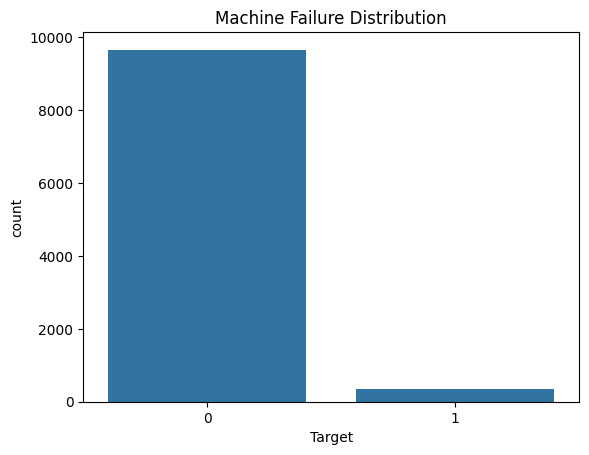

In [ ]:
# Dataset information
print("Dataset Information:")
print(df.info())

# Statistical analysis
print("\nStatistical Description:")
print(df.describe())

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Target distribution
print("\nTarget Distribution:")
print(df["Target"].value_counts())

# Visualize target
sns.countplot(data=df, x="Target")
plt.title("Machine Failure Distribution")
plt.show()

In [ ]:
print(df.columns.tolist())

['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target']


In [ ]:
# Separate input and output

X = df.drop("Target", axis=1)

y = df["Target"]

# Convert categorical Type into numerical values

X = pd.get_dummies(
    X,
    columns=["Type"],
    drop_first=True,
    dtype=int
)

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

print(X.head())

Input Shape: (10000, 7)
Output Shape: (10000,)
   Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0                298.1                    308.6                    1551   
1                298.2                    308.7                    1408   
2                298.1                    308.5                    1498   
3                298.2                    308.6                    1433   
4                298.2                    308.7                    1408   

   Torque [Nm]  Tool wear [min]  Type_L  Type_M  
0         42.8                0       0       1  
1         46.3                3       1       0  
2         49.4                5       1       0  
3         39.5                7       1       0  
4         40.0                9       1       0  


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (8000, 7)
Testing: (2000, 7)


In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print("Scaling completed")

Scaling completed


In [ ]:
model = Sequential([

    Input(shape=(X_train.shape[1],)),

    Dense(64, activation="relu"),

    Dense(32, activation="relu"),

    Dense(16, activation="relu"),

    Dense(1, activation="sigmoid")

])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,137 (12.25 KB)

 Trainable params: 3,137 (12.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=["accuracy"]

)

print("Model Compiled Successfully")

Model Compiled Successfully


In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(

    X_train,
    y_train,

    epochs=50,

    batch_size=32,

    validation_split=0.2,

    callbacks=[early_stop],

    verbose=1

)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9653 - loss: 0.1853 - val_accuracy: 0.9656 - val_loss: 0.1281
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9681 - loss: 0.1044 - val_accuracy: 0.9719 - val_loss: 0.0972
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9722 - loss: 0.0891 - val_accuracy: 0.9700 - val_loss: 0.0958
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9727 - loss: 0.0821 - val_accuracy: 0.9706 - val_loss: 0.0843
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9742 - loss: 0.0790 - val_accuracy: 0.9750 - val_loss: 0.0835
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9734 - loss: 0.0767 - val_accuracy: 0.9706 - val_loss: 0.0779
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9755 - loss: 0.0727 - val_accuracy: 0.9706 - val_loss: 0.0794
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9758 - loss: 0.0722 - val_accuracy: 0.

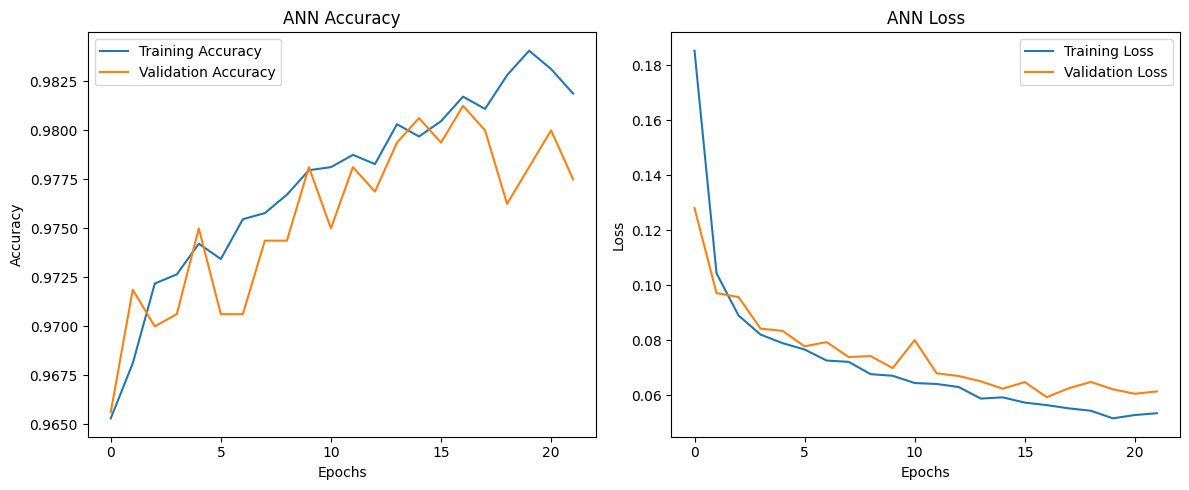

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"],
         label="Training Accuracy")

plt.plot(history.history["val_accuracy"],
         label="Validation Accuracy")

plt.title("ANN Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()


# Loss
plt.subplot(1, 2, 2)

plt.plot(history.history["loss"],
         label="Training Loss")

plt.plot(history.history["val_loss"],
         label="Validation Loss")

plt.title("ANN Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.tight_layout()

plt.show()

In [ ]:
loss, accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test Loss:", loss)

print("Test Accuracy:", accuracy)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9790 - loss: 0.0626
Test Loss: 0.0626463070511818
Test Accuracy: 0.9789999723434448


In [ ]:
# Predict probabilities
y_probability = model.predict(X_test)

# Convert probability into class
y_pred = (y_probability >= 0.5).astype(int)

print("Actual Values:")
print(y_test.values[:10])

print("\nPredicted Values:")
print(y_pred[:10].flatten())

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Actual Values:
[0 0 0 0 0 0 0 0 0 0]

Predicted Values:
[0 0 0 0 0 0 0 0 0 0]


In [ ]:
# Example machine details
new_machine = pd.DataFrame([{
    "Air temperature [K]": 300.5,
    "Process temperature [K]": 310.0,
    "Rotational speed [rpm]": 1500,
    "Torque [Nm]": 40.0,
    "Tool wear [min]": 100,
    "Type_M": 1,
    "Type_L": 0
}])

# Ensure same feature order
new_machine = new_machine[X.columns]

# Scale input
new_machine_scaled = scaler.transform(new_machine)

# Prediction
probability = model.predict(new_machine_scaled)[0][0]

print("Failure Probability:", probability)

if probability >= 0.5:
    print("Prediction: Machine Failure")
else:
    print("Prediction: No Machine Failure")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Failure Probability: 0.0005652094
Prediction: No Machine Failure
